# Check bubble contours

Use **Godfather**. Run top to bottom, then choose a candidate in the dropdown.
This is an inspection experiment: it never changes narration predictions or speaker assignments.
It reuses page-matched Magi boxes and YOLO candidates, including rejected candidates.
If absent, it creates only missing detection caches using the local models; no OCR or embeddings are extracted.

We look for an enclosing boundary, white interior outside text, a margin, and shape evidence.
Padding is **20% of candidate width/height on each side**. Closed mixed flat/curved
shapes (including rounded rectangles) are measured as well as rounded and rectangular outlines.
Green means a provisional rounded/white or mixed flat/curved candidate; orange means a rectangular candidate;
gray means uncertain. **These are heuristic observations, not verified speech/narration labels.**
Each crop now records `enclosed_boundary_found` independently of white/shape checks.
A separate merge pass includes verified neighbors when at least one overlapping member lacks a boundary.

Crop-edge segments never count as drawn outline evidence. Tables distinguish real supported enclosure from crop-truncated regions, which remain eligible for merging.


## 1. Settings and detection-cache discovery

Choose a page and adjust thresholds here. Existing pipeline files are read only. This notebook owns a separate contour cache.

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
import torch  # Import before other GPU libraries on this machine.
import gc, json, hashlib, math, importlib.util
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from PIL import Image
from IPython.display import display

PROJECT = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi')
EXPERIMENT = PROJECT / 'FINETUNING-EXPERMENTS/NarrationModelwBubbles'
SEQUENCE_ID = 'seq_06ec0acde37dffa4'
SPLIT = 'development'
PAGE_NUMBER = 2
PAGE_PATH = PROJECT / 'TaskData' / SPLIT / 'images' / SEQUENCE_ID / f'{PAGE_NUMBER:02d}.png'
# Alternatively set PAGE_PATH to any local page image. Matching cached boxes are found by image hash.
CACHE = PROJECT / 'paddleOCR-Magi/cache_contour'
BUBBLE_MODEL = Path(r'C:\MODELS\manga_bubbles\bubbles_detect.pt')
MAGI_MODEL = Path(r'C:\MODELS\magiv2')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DETECTION = dict(imgsz=1024, confidence=0.25)
CHECK = dict(expand=0.20, dark_threshold=180, white_threshold=210,
             close_kernel=3, text_padding=2, min_text_coverage=0.95,
             min_white_fraction=0.85, min_border_dark_fraction=0.20,
             min_candidate_iou=0.35, max_area_ratio=1.7,
             rectangle_fill=0.88, rounded_max_fill=0.90, min_solidity=0.85,
             boundary_samples=256, curve_window=12, straight_tolerance_px=0.8,
             straight_tolerance_fraction=0.015, sharp_turn_deg=18,
             mixed_min_flat=0.15, mixed_min_curved=0.12,
             crop_edge_margin_px=1, max_crop_edge_fraction=0.02,
             min_supported_boundary_fraction=0.85, max_unsupported_fraction=0.10)
# Only failed enclosure checks receive the additional faint-outline attempt.
FAINT = dict(enabled=True, local_window=15, min_local_contrast=7,
             max_line_gray=245, close_kernel=3)
FORCE_DETECTIONS = False
assert PAGE_PATH.is_file(), f'Missing page: {PAGE_PATH}'
assert CHECK['close_kernel'] >= 1 and CHECK['close_kernel'] % 2 == 1

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def key(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,default=str).encode()).hexdigest()

PAGE_HASH = sha256(PAGE_PATH)
image = Image.open(PAGE_PATH).convert('RGB')
CACHE.mkdir(parents=True, exist_ok=True)
print('Page:', PAGE_PATH, '| size:', image.size)
print('Contour cache:', CACHE)


Page: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_06ec0acde37dffa4\02.png | size: (848, 1250)
Contour cache: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_contour


## 2. Reuse or create text boxes

Text boxes tell us which pixels to exclude when testing the interior. Reuse compatible Magi detections; if missing, run local Magi detection only.

In [2]:
def cached_text_boxes():
    roots = [EXPERIMENT / 'cache_selected_ocr/full_pipeline',
             PROJECT / 'paddleOCR-Magi/cache_inference']
    for root in roots:
        for manifest_path in sorted(root.rglob('manifest.json')):
            raw_path = manifest_path.with_name('magi_raw.json')
            if not raw_path.is_file():
                continue
            try:
                manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
                payload = json.loads(raw_path.read_text(encoding='utf-8'))
                # Existing full-pipeline cache checksums use this canonical JSON representation.
                checksum = hashlib.sha256(json.dumps(payload['data'], sort_keys=True,
                    ensure_ascii=True, allow_nan=False).encode('utf-8')).hexdigest()
                if checksum != payload['data_hash']:
                    continue
                for index, page in enumerate(manifest['inputs']['pages']):
                    if page['sha256'] == PAGE_HASH and (page['width'],page['height']) == image.size:
                        return payload['data'][index]['texts'], str(raw_path)
            except (KeyError, ValueError, OSError, IndexError):
                continue
    return None, None

texts, text_source = cached_text_boxes() if not FORCE_DETECTIONS else (None, None)
if texts is None:
    # Content hashes make this small detection cache independent of the source filename.
    identity = dict(page=PAGE_HASH, model=str(MAGI_MODEL),
                    weights={p.name:sha256(p) for p in MAGI_MODEL.glob('*.safetensors')}, version=1)
    text_cache = CACHE / ('texts_' + key(identity)[:20] + '.json')
    if text_cache.is_file() and not FORCE_DETECTIONS:
        texts = json.loads(text_cache.read_text(encoding='utf-8'))['texts']
    else:
        spec = importlib.util.spec_from_file_location('contour_magi_helper', EXPERIMENT / 'bubble_features.py')
        helper = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(helper)
        model = helper.load_magi(MAGI_MODEL, DEVICE)
        try:
            with torch.inference_mode():
                page = np.asarray(image.convert('L').convert('RGB'))
                result = model.do_chapter_wide_prediction([page], {'images':[], 'names':[]}, do_ocr=False)[0]
            texts = np.asarray(result['texts']).reshape(-1,4).tolist()
            text_cache.write_text(json.dumps(dict(identity=identity,texts=texts)), encoding='utf-8')
        finally:
            del model
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    text_source = str(text_cache)
print('Text boxes:', len(texts), '| source:', text_source)


Text boxes: 16 | source: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_contour\texts_2765199bc9ec376f657c.json


## 3. Reuse or create YOLO bubble candidates

Read cached candidate rectangles, including ones rejected by the OCR filter. Missing candidates run only the local bubble detector.

In [3]:
def cached_bubbles():
    root = EXPERIMENT / 'cache_selected_ocr/bubbles'
    for path in sorted(root.rglob('bubbles.json')):
        try:
            saved = json.loads(path.read_text(encoding='utf-8'))
            settings = saved['identity']['settings']
            if (saved['page']['sha256'] == PAGE_HASH
                and saved['identity']['detector_sha256'] == sha256(BUBBLE_MODEL)
                and settings['bubble_imgsz'] == DETECTION['imgsz']
                and settings['bubble_confidence'] == DETECTION['confidence']):
                return [dict(box=b['box'],confidence=b['confidence'],
                             originally_kept=b.get('kept')) for b in saved['bubbles']], str(path)
        except (KeyError,ValueError,OSError):
            continue
    return None, None

assert BUBBLE_MODEL.is_file(), f'Missing local bubble detector: {BUBBLE_MODEL}'
candidates, bubble_source = cached_bubbles() if not FORCE_DETECTIONS else (None, None)
if candidates is None:
    identity = dict(page=PAGE_HASH, weights=sha256(BUBBLE_MODEL), settings=DETECTION, version=1)
    bubble_cache = CACHE / ('bubbles_' + key(identity)[:20] + '.json')
    if bubble_cache.is_file() and not FORCE_DETECTIONS:
        candidates = json.loads(bubble_cache.read_text(encoding='utf-8'))['candidates']
    else:
        from ultralytics import YOLO
        detector = YOLO(str(BUBBLE_MODEL))
        try:
            result = detector.predict(source=image, imgsz=DETECTION['imgsz'],
                conf=DETECTION['confidence'], device=DEVICE, verbose=False)[0]
            candidates = []
            for box, confidence in zip(result.boxes.xyxy.cpu().tolist(),result.boxes.conf.cpu().tolist()):
                x1,y1,x2,y2 = box
                box = [max(0,math.floor(x1)),max(0,math.floor(y1)),
                       min(image.width,math.ceil(x2)),min(image.height,math.ceil(y2))]
                if box[2]>box[0] and box[3]>box[1]:
                    candidates.append(dict(box=box,confidence=float(confidence),originally_kept=None))
            candidates.sort(key=lambda b:(b['box'][1],-b['box'][0]))
            bubble_cache.write_text(json.dumps(dict(identity=identity,candidates=candidates)),encoding='utf-8')
        finally:
            del detector
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    bubble_source = str(bubble_cache)
print('YOLO candidates:',len(candidates),'| source:',bubble_source)


YOLO candidates: 13 | source: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\bubbles\development\seq_06ec0acde37dffa4\page_02\2e4c7922a217d8f9\bubbles.json


## 4. Contour checks

Find closed dark outlines and enclosed white regions. Keep edge-touching contours; reject boundaries that do not surround the text. Measure straight, smoothly curved and sharp boundary fractions, plus whiteness.
Closed outlines must still surround text and pass the interior/margin checks. Contours remain eligible when they touch the crop edge. However, crop-border segments are excluded from ink evidence. A contour relying on a significant crop-edge segment is labeled crop-truncated, not enclosed.

In [4]:
def boundary_profile(contour, settings):
    """Sample a closed boundary evenly; distinguish straight, smooth-curved and sharp sections."""
    points = contour[:, 0].astype(float)
    points = np.vstack([points, points[0]])
    lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    keep = np.r_[True, lengths > 1e-8]
    points = points[keep]
    lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    distance = np.r_[0., np.cumsum(lengths)]
    samples = np.linspace(0, distance[-1], settings['boundary_samples'], endpoint=False)
    boundary = np.column_stack([np.interp(samples, distance, points[:, axis]) for axis in [0, 1]])
    # Mild periodic smoothing suppresses pixel stair-steps without fitting an ellipse.
    smooth = sum(weight*np.roll(boundary, shift, axis=0)
                 for shift,weight in [(-2,1),(-1,4),(0,6),(1,4),(2,1)])/16
    previous, following = smooth-np.roll(smooth,1,axis=0), np.roll(smooth,-1,axis=0)-smooth
    cosine = (previous*following).sum(1)/np.maximum(1e-8,
                np.linalg.norm(previous,axis=1)*np.linalg.norm(following,axis=1))
    turning = np.degrees(np.arccos(np.clip(cosine,-1,1)))
    window = settings['curve_window']
    a,b = np.roll(smooth,window,axis=0),np.roll(smooth,-window,axis=0)
    chord = b-a
    chord_length = np.linalg.norm(chord,axis=1)
    offset = smooth-a
    deviation = np.abs(chord[:,0]*offset[:,1]-chord[:,1]*offset[:,0])/np.maximum(1e-8,chord_length)
    tolerance = np.maximum(settings['straight_tolerance_px'],
                           settings['straight_tolerance_fraction']*chord_length)
    # A sharp corner is not itself evidence of a smooth curve. Mark its neighborhood separately.
    sharp = np.maximum.reduce([np.roll(turning,shift) for shift in range(-window,window+1)]) > settings['sharp_turn_deg']
    flat = (deviation <= tolerance) & ~sharp
    curved = (deviation > tolerance) & ~sharp
    labels = np.full(len(boundary),'sharp',dtype=object)
    labels[flat],labels[curved] = 'flat','curved'
    return dict(boundary_points=boundary,boundary_labels=labels,
                flat_fraction=float(flat.mean()),curved_fraction=float(curved.mean()),
                sharp_fraction=float(sharp.mean()))


def overlap(a,b):
    return max(0,min(a[2],b[2])-max(a[0],b[0])) * max(0,min(a[3],b[3])-max(a[1],b[1]))

def faint_ink_mask(gray, settings):
    """Recover gray strokes darker than their local background; never invent a crop border."""
    window=settings['local_window']
    # A local bright background exposes faint gray outlines beside white bubble interiors.
    background=cv2.morphologyEx(gray,cv2.MORPH_CLOSE,np.ones((window,window),np.uint8))
    contrast=background.astype(np.int16)-gray.astype(np.int16)
    return np.uint8((gray < settings['dark_threshold']) |
                   ((contrast >= settings['min_local_contrast']) &
                    (gray <= settings['max_line_gray'])))*255


def drawn_boundary_evidence(profile, gray, text_mask, settings):
    """Crop-border segments supply no outline evidence, even when OpenCV closes them."""
    points=np.rint(profile['boundary_points']).astype(int)
    height,width=gray.shape
    edge_margin=settings['crop_edge_margin_px']
    on_edge=((points[:,0]<=edge_margin)|(points[:,1]<=edge_margin)
             |(points[:,0]>=width-1-edge_margin)|(points[:,1]>=height-1-edge_margin))
    ink=faint_ink_mask(gray,settings)>0 if settings.get('faint_retry') else gray<settings['dark_threshold']
    raw_dark=np.uint8(ink & (text_mask==0))
    # Look for actual ink near each contour point, allowing a small white/black contour offset.
    raw_dark[:edge_margin+1,:]=0
    raw_dark[-edge_margin-1:,:]=0
    raw_dark[:,:edge_margin+1]=0
    raw_dark[:,-edge_margin-1:]=0
    nearby=cv2.dilate(raw_dark,np.ones((5,5),np.uint8))
    supported=(nearby[points[:,1],points[:,0]]>0)&~on_edge
    # Measure the longest unsupported run around the complete circular boundary.
    missing=~supported
    longest=current=0
    for value in np.r_[missing,missing]:
        current=current+1 if value else 0
        longest=max(longest,current)
    longest=min(longest,len(points))
    labels=profile['boundary_labels'].copy()
    labels[on_edge]='crop_edge'
    valid=max(1,np.count_nonzero(~on_edge))
    return dict(boundary_labels=labels,
        flat_fraction=float(np.count_nonzero(labels=='flat')/valid),
        curved_fraction=float(np.count_nonzero(labels=='curved')/valid),
        sharp_fraction=float(np.count_nonzero(labels=='sharp')/valid),
        crop_edge_fraction=float(on_edge.mean()),
        supported_boundary_fraction=float(supported.mean()),
        longest_unsupported_fraction=float(longest/len(points)),
        crop_truncated=bool(on_edge.mean()>settings['max_crop_edge_fraction']))


def check_candidate(candidate, page_image, text_boxes, settings, required_text_indices=None):
    x1,y1,x2,y2 = candidate['box']
    dx,dy = (x2-x1)*settings['expand'],(y2-y1)*settings['expand']
    bounds = [max(0,math.floor(x1-dx)),max(0,math.floor(y1-dy)),
              min(page_image.width,math.ceil(x2+dx)),min(page_image.height,math.ceil(y2+dy))]
    crop = np.asarray(page_image.crop(bounds))
    gray = cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)
    dark = (faint_ink_mask(gray,settings) if settings.get('faint_retry')
            else np.uint8(gray < settings['dark_threshold'])*255)
    kernel = np.ones((settings['close_kernel'],settings['close_kernel']),np.uint8)
    closed = cv2.morphologyEx(dark,cv2.MORPH_CLOSE,kernel)
    white = np.uint8(gray >= settings['white_threshold'])*255
    # All nearby text is excluded from whiteness; the candidate's contained text must be enclosed.
    text_mask = np.zeros_like(gray,np.uint8)
    required = np.zeros_like(gray,np.uint8)
    associated = []
    for index,box in enumerate(text_boxes):
        if overlap(box,bounds)<=0: continue
        a,b,c,d = box
        pad = settings['text_padding']
        left,top = max(0,math.floor(a-bounds[0]-pad)),max(0,math.floor(b-bounds[1]-pad))
        right,bottom = min(gray.shape[1],math.ceil(c-bounds[0]+pad)),min(gray.shape[0],math.ceil(d-bounds[1]+pad))
        text_mask[top:bottom,left:right]=255
        area = max(1,(c-a)*(d-b))
        if (index in required_text_indices if required_text_indices is not None
            else overlap(box,candidate['box'])/area >= 0.8):
            # Use unexpanded text rectangles for the enclosure requirement.
            left,top=max(0,math.floor(a-bounds[0])),max(0,math.floor(b-bounds[1]))
            right,bottom=min(gray.shape[1],math.ceil(c-bounds[0])),min(gray.shape[0],math.ceil(d-bounds[1]))
            required[top:bottom,left:right]=255
            associated.append(index)
    contours = []
    # On retry, trace spaces separated by recovered faint ink as well as ink contours.
    binaries=[closed,cv2.bitwise_not(closed)] if settings.get('faint_retry') else [closed,white]
    for binary in binaries:
        found,_ = cv2.findContours(binary,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
        contours.extend(found)
    records = []
    target = [x1-bounds[0],y1-bounds[1],x2-bounds[0],y2-bounds[1]]
    target_area = max(1,(x2-x1)*(y2-y1))
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 25 or area > target_area*settings['max_area_ratio']: continue
        x,y,w,h = cv2.boundingRect(contour)
        # Edge-touching contours are evaluated by the same text/interior/shape checks.
        inter = overlap([x,y,x+w,y+h],target)
        iou = inter/max(1,w*h+target_area-inter)
        if iou < settings['min_candidate_iou']: continue
        mask = np.zeros_like(gray,np.uint8)
        cv2.drawContours(mask,[contour],-1,255,cv2.FILLED)
        coverage = np.count_nonzero((mask>0)&(required>0))/max(1,np.count_nonzero(required))
        interior = cv2.erode(mask,np.ones((3,3),np.uint8),iterations=2)
        usable = (interior>0)&(text_mask==0)
        whiteness = float((gray[usable]>=settings['white_threshold']).mean()) if usable.any() else 0.
        # Sample a narrow ring around the contour on the original image, not the repaired mask.
        ring = cv2.dilate(mask,np.ones((5,5),np.uint8))-cv2.erode(mask,np.ones((5,5),np.uint8))
        # Do not let an image-border segment count as a dark drawn outline.
        valid_ring=(ring>0)&(text_mask==0)
        edge=settings['crop_edge_margin_px']+1
        valid_ring[:edge,:]=False; valid_ring[-edge:,:]=False
        valid_ring[:,:edge]=False; valid_ring[:,-edge:]=False
        outline_ink=(dark>0) if settings.get('faint_retry') else gray<settings['dark_threshold']
        border_dark=float(outline_ink[valid_ring].mean()) if valid_ring.any() else 0.
        perimeter = cv2.arcLength(contour,True)
        approx = cv2.approxPolyDP(contour,0.025*perimeter,True)
        rect = cv2.minAreaRect(contour)
        rect_area = rect[1][0]*rect[1][1]
        fill = area/max(1,rect_area)
        solidity = area/max(1,cv2.contourArea(cv2.convexHull(contour)))
        yy,xx = np.where(required>0)
        margin = float(min(xx.min()-x,yy.min()-y,x+w-1-xx.max(),y+h-1-yy.max())) if len(xx) else 0.
        reasons = []
        if not associated: reasons.append('no contained text')
        if coverage<settings['min_text_coverage']: reasons.append('does not enclose text')
        # OCR-box margin is diagnostic only: loose rectangles can touch a valid outline.
        if whiteness<settings['min_white_fraction']: reasons.append('interior not mostly white')
        if border_dark<settings['min_border_dark_fraction']: reasons.append('weak dark outline')
        profile = boundary_profile(contour,settings)
        profile.update(drawn_boundary_evidence(profile,gray,text_mask,settings))
        if profile['crop_truncated']:
            reasons.append('crop-truncated region; crop edge is not outline evidence')
        if profile['supported_boundary_fraction'] < settings['min_supported_boundary_fraction']:
            reasons.append('insufficient real drawn boundary support')
        if profile['longest_unsupported_fraction'] > settings['max_unsupported_fraction']:
            reasons.append('long unsupported boundary gap')
        # Rounded rectangles and flat-sided curved bubbles can fill almost their entire rectangle.
        mixed = (profile['flat_fraction'] >= settings['mixed_min_flat']
                 and profile['curved_fraction'] >= settings['mixed_min_curved']
                 and solidity >= settings['min_solidity'])
        rectangular = len(approx)==4 and fill>=settings['rectangle_fill'] and not mixed
        rounded = (profile['curved_fraction'] >= settings['mixed_min_curved']
                   and len(approx)>=5 and fill<settings['rounded_max_fill']
                   and solidity>=settings['min_solidity'])
        shape = 'mixed_flat_curved' if mixed else 'rectangular' if rectangular else 'rounded' if rounded else 'ambiguous'
        status = ({'mixed_flat_curved':'mixed_flat_curved_candidate','rectangular':'rectangular_candidate',
                   'rounded':'rounded_white_candidate'}.get(shape,'uncertain')) if not reasons else 'uncertain'
        if shape=='ambiguous': reasons.append('ambiguous shape')
        # Enclosure is independent of whiteness and whether the boundary is round or rectangular.
        enclosed_boundary_found = bool(associated
            and coverage >= settings['min_text_coverage']
            and border_dark >= settings['min_border_dark_fraction']
            and not profile['crop_truncated']
            and profile['supported_boundary_fraction'] >= settings['min_supported_boundary_fraction']
            and profile['longest_unsupported_fraction'] <= settings['max_unsupported_fraction'])
        score = coverage + whiteness + border_dark + iou + profile['supported_boundary_fraction'] + (1 if not reasons else 0)
        records.append(dict(enclosed_boundary_found=enclosed_boundary_found,**profile,contour=contour,mask=mask,usable=usable,score=score,
            coverage=coverage,white_fraction=whiteness,border_dark_fraction=border_dark,
            margin_px=margin,vertices=len(approx),rectangularity=fill,solidity=solidity,
            candidate_iou=iou,shape=shape,status=status,reasons='; '.join(reasons) or 'passed provisional checks'))
    best = max(records,key=lambda r:r['score']) if records else None
    boundaries = [r for r in records if r['enclosed_boundary_found']]
    boundary_best = max(boundaries,key=lambda r:r['score']) if boundaries else None
    return dict(crop=crop,dark=dark,closed=closed,text_mask=text_mask,required=required,
                bounds=bounds,associated_text_indices=associated,contours=records,best=best,
                enclosed_boundary_found=bool(boundaries),boundary_best=boundary_best,
                boundary_kind='drawn_enclosed' if boundaries else 'crop_truncated' if best and best['crop_truncated'] else 'not_verified')


def check_with_faint_retry(candidate, page_image, text_boxes, settings, required_text_indices=None):
    """Keep first-pass successes intact; retry failures on the SAME crop with local contrast."""
    first=check_candidate(candidate,page_image,text_boxes,settings,required_text_indices)
    first['detection_pass']='first'
    first['faint_retry_attempted']=False
    if first['enclosed_boundary_found'] or not FAINT['enabled']:
        return first
    retry_settings=dict(settings, **{k:v for k,v in FAINT.items() if k!='enabled'})
    retry_settings['faint_retry']=True
    retry=check_candidate(candidate,page_image,text_boxes,retry_settings,required_text_indices)
    # Preserve the failed first result for comparison, even when the retry recovers an outline.
    first['faint_retry_attempted']=True
    first['faint_retry_result']=retry
    if not retry['enclosed_boundary_found']:
        return first
    retry['detection_pass']='faint_retry'
    retry['faint_retry_attempted']=True
    retry['first_pass_result']=first
    return retry


**Failed checks only: faint-outline retry.** The original pass runs first. An enclosed boundary found there is returned unchanged. Only failures retry with local gray-stroke contrast on the same crop; padding, white-interior, support and crop-edge requirements stay unchanged. OCR-box margin is recorded for inspection only and never rejects an enclosure. Tables show `detection_pass` and `faint_retry_attempted`. Failed retry details remain available in `result["faint_retry_result"]`; recovered results retain `result["first_pass_result"]`. No models or OCR rerun for this step.

## 5. Page overview and scores

Run every candidate through the checks. This table is diagnostic only; a rectangular candidate is not automatically narration.

,detection_pass,faint_retry_attempted,boundary_kind,enclosed_boundary_found,index,confidence,originally_kept,texts,status,reasons,...,rectangularity,solidity,shape,flat_fraction,curved_fraction,sharp_fraction,crop_edge_fraction,supported_boundary_fraction,longest_unsupported_fraction,crop_truncated
0,first,True,crop_truncated,False,0,0.781944,True,[0],uncertain,does not enclose text; crop-truncated region; ...,...,0.753632,0.921167,mixed_flat_curved,0.259109,0.449393,0.291498,0.035156,0.664062,0.187500,True
1,first,True,crop_truncated,False,1,0.871232,True,[5],uncertain,crop-truncated region; crop edge is not outlin...,...,0.627929,0.754581,ambiguous,0.000000,0.042857,0.957143,0.179688,0.406250,0.332031,True
2,first,False,drawn_enclosed,True,2,0.448880,True,[1],rounded_white_candidate,passed provisional checks,...,0.671774,0.875180,rounded,0.136719,0.390625,0.472656,0.000000,0.925781,0.062500,False
3,first,True,crop_truncated,False,3,0.896847,True,[6],uncertain,crop-truncated region; crop edge is not outlin...,...,0.674251,0.793421,ambiguous,0.061905,0.057143,0.880952,0.179688,0.628906,0.371094,True
4,first,True,crop_truncated,False,4,0.455356,False,[],uncertain,no contained text; does not enclose text; crop...,...,0.273077,0.291781,ambiguous,0.000000,0.032787,0.967213,0.285156,0.714844,0.167969,True
5,first,True,crop_truncated,False,5,0.254403,False,[],uncertain,no contained text; does not enclose text; inte...,...,0.536663,0.676272,ambiguous,0.000000,0.000000,1.000000,0.062500,0.937500,0.039062,True
6,first,False,drawn_enclosed,True,6,0.905603,True,[7],mixed_flat_curved_candidate,passed provisional checks,...,0.802938,0.967440,mixed_flat_curved,0.164062,0.496094,0.339844,0.000000,0.972656,0.027344,False
7,first,False,drawn_enclosed,True,7,0.920630,True,[12],uncertain,ambiguous shape,...,0.770662,0.878400,ambiguous,0.058594,0.234375,0.707031,0.000000,1.000000,0.000000,False
8,first,False,drawn_enclosed,True,8,0.928940,True,[11],rounded_white_candidate,passed provisional checks,...,0.816113,0.944963,rounded,0.105469,0.648438,0.246094,0.000000,1.000000,0.000000,False
9,first,True,crop_truncated,False,9,0.670826,True,[8],uncertain,crop-truncated region; crop edge is not outlin...,...,0.778566,0.801948,ambiguous,0.274611,0.062176,0.663212,0.246094,0.390625,0.261719,True


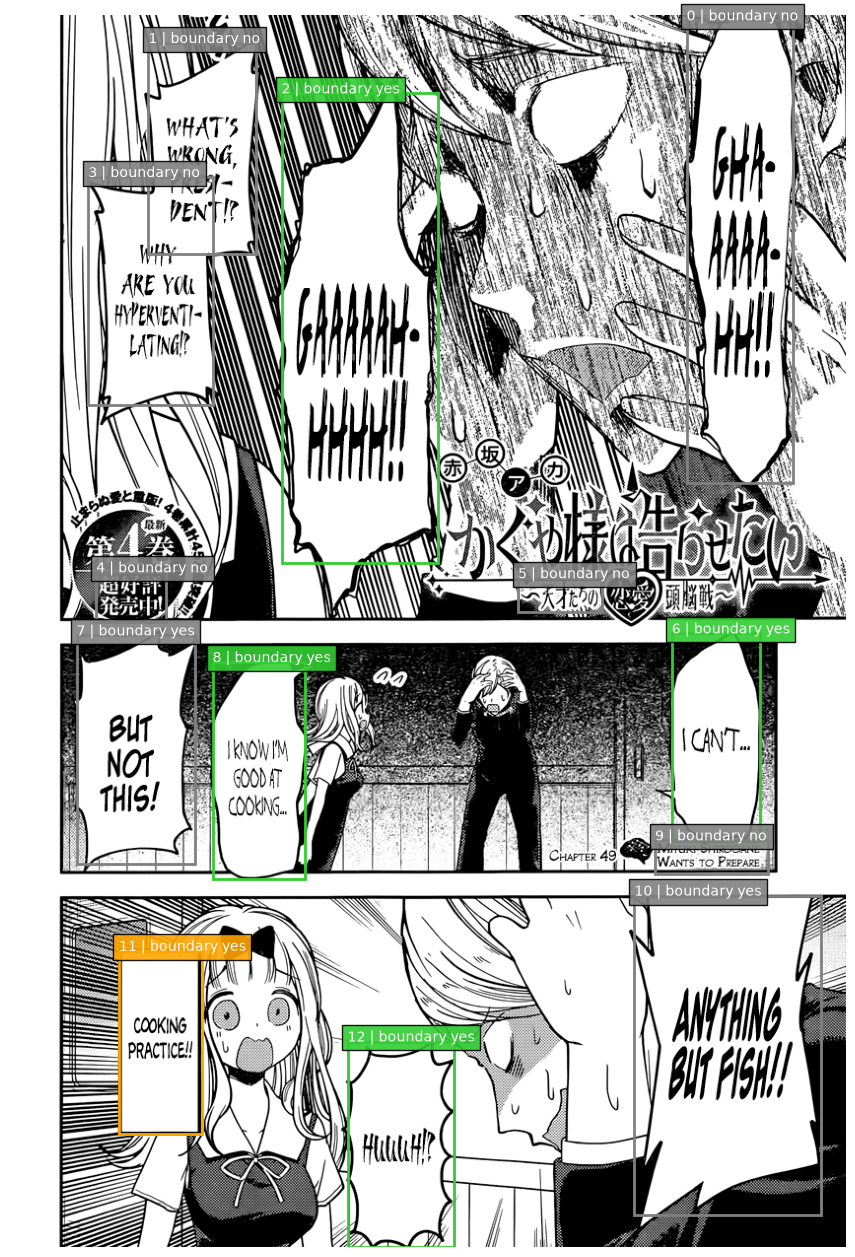

In [5]:
checks = [check_with_faint_retry(candidate,image,texts,CHECK) for candidate in candidates]
rows = []
for index,(candidate,result) in enumerate(zip(candidates,checks)):
    best = result['boundary_best'] or result['best']
    row = dict(detection_pass=result['detection_pass'],faint_retry_attempted=result['faint_retry_attempted'],boundary_kind=result['boundary_kind'],enclosed_boundary_found=result['enclosed_boundary_found'],index=index,confidence=candidate['confidence'],originally_kept=candidate.get('originally_kept'),
               texts=result['associated_text_indices'],status=best['status'] if best else 'uncertain',
               reasons=best['reasons'] if best else 'no qualifying enclosing contour')
    if best:
        row.update({k:best[k] for k in ['white_fraction','border_dark_fraction','coverage','margin_px',
                                      'vertices','rectangularity','solidity','shape','flat_fraction','curved_fraction','sharp_fraction','crop_edge_fraction','supported_boundary_fraction','longest_unsupported_fraction','crop_truncated']})
    rows.append(row)
scores = pd.DataFrame(rows) if rows else pd.DataFrame(columns=['index','enclosed_boundary_found','status'])
display(scores)
fig,ax=plt.subplots(figsize=(12,16))
ax.imshow(image)
for index,(candidate,result) in enumerate(zip(candidates,checks)):
    best=result['best']
    color = 'limegreen' if best and best['status'] in {'rounded_white_candidate','mixed_flat_curved_candidate'} else 'orange' if best and best['status']=='rectangular_candidate' else 'gray'
    x1,y1,x2,y2=candidate['box']
    ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=2))
    ax.text(x1,y1,f"{index} | boundary {'yes' if result['enclosed_boundary_found'] else 'no'}",color='white',bbox=dict(facecolor=color,alpha=.9))
ax.axis('off')
plt.show()


## 6. Inspect contours and masks

Select a candidate. Blue boxes mark text, yellow marks the YOLO rectangle, and the selected enclosing contour is colored by section: cyan flat, green curved, orange sharp, red artificial crop-edge segments. White in the final panel is the measured interior; blue is excluded text.

interactive(children=(Dropdown(description='Candidate:', options=(('0: boundary=False | uncertain', 0), ('1: b…

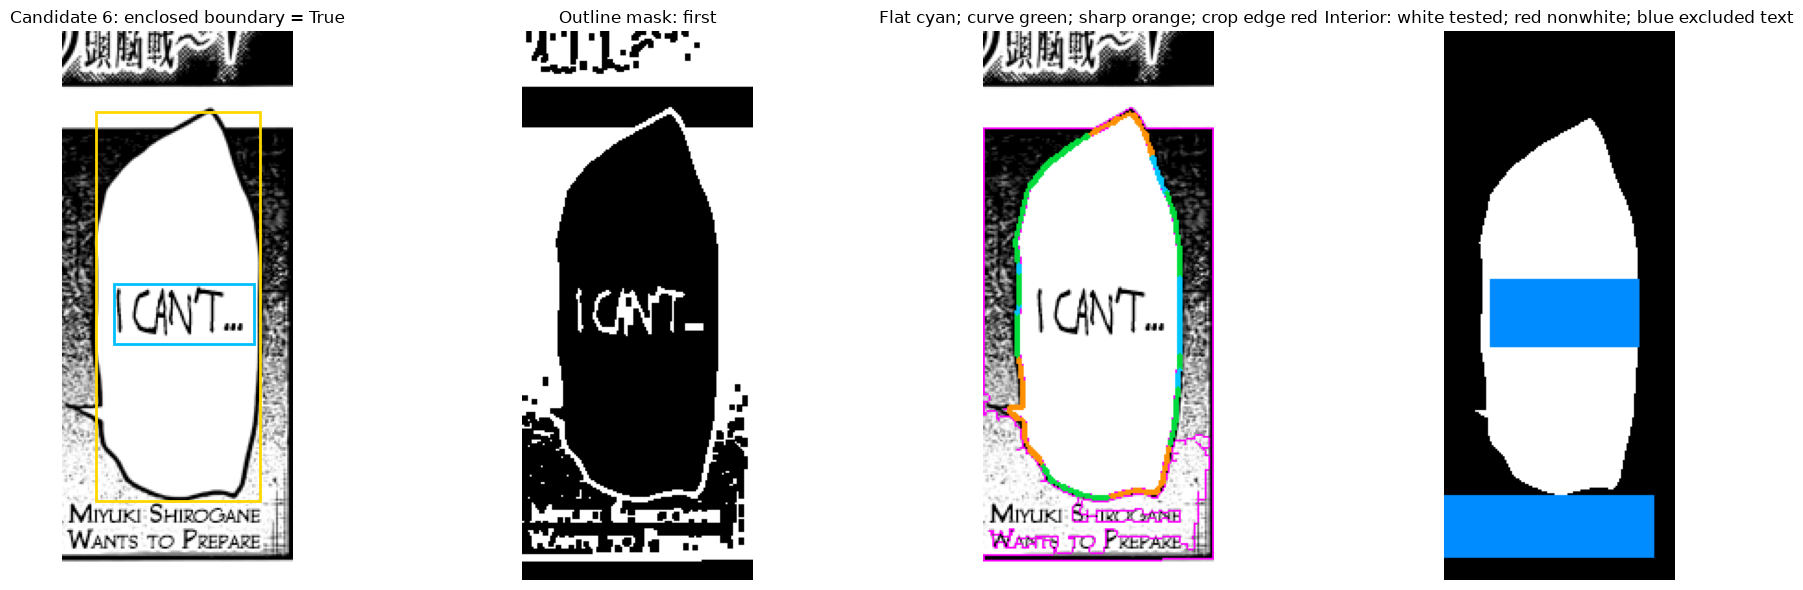

,detection_pass,faint_retry_attempted,boundary_kind,enclosed_boundary_found,index,confidence,originally_kept,texts,status,reasons,...,rectangularity,solidity,shape,flat_fraction,curved_fraction,sharp_fraction,crop_edge_fraction,supported_boundary_fraction,longest_unsupported_fraction,crop_truncated
6,first,False,drawn_enclosed,True,6,0.905603,True,[7],mixed_flat_curved_candidate,passed provisional checks,...,0.802938,0.96744,mixed_flat_curved,0.164062,0.496094,0.339844,0.0,0.972656,0.027344,False


,enclosed_boundary_found,flat_fraction,curved_fraction,sharp_fraction,crop_edge_fraction,supported_boundary_fraction,longest_unsupported_fraction,crop_truncated,score,coverage,white_fraction,border_dark_fraction,margin_px,vertices,rectangularity,solidity,candidate_iou,shape,status,reasons
0,True,0.164062,0.496094,0.339844,0.000000,0.972656,0.027344,False,5.583591,1.0,1.000000,0.662630,3.0,7,0.802938,0.967440,0.948305,mixed_flat_curved,mixed_flat_curved_candidate,passed provisional checks
1,True,0.164062,0.488281,0.347656,0.000000,0.972656,0.027344,False,5.358497,1.0,1.000000,0.485307,2.0,6,0.772854,0.951448,0.900534,mixed_flat_curved,mixed_flat_curved_candidate,passed provisional checks
2,False,0.000000,0.000000,1.000000,0.285156,0.402344,0.187500,True,3.086327,1.0,0.623724,0.449559,21.0,8,0.813298,0.832213,0.610699,ambiguous,uncertain,interior not mostly white; crop-truncated regi...


In [6]:
def inspect_candidate(index=0,show_other_contours=True):
    if not checks:
        print('No YOLO candidates on this page. Select another page.')
        return
    result,candidate=checks[index],candidates[index]
    best=result['boundary_best'] or result['best']
    crop=result['crop']
    fig,axes=plt.subplots(1,4,figsize=(20,6))
    axes[0].imshow(crop)
    left,top,_,_=result['bounds']
    x1,y1,x2,y2=candidate['box']
    axes[0].add_patch(patches.Rectangle((x1-left,y1-top),x2-x1,y2-y1,fill=False,edgecolor='gold',linewidth=2))
    for i in result['associated_text_indices']:
        a,b,c,d=texts[i]
        axes[0].add_patch(patches.Rectangle((a-left,b-top),c-a,d-b,fill=False,edgecolor='deepskyblue',linewidth=2))
    axes[0].set_title(f"Candidate {index}: enclosed boundary = {result['enclosed_boundary_found']}")
    axes[1].imshow(result['closed'],cmap='gray',vmin=0,vmax=255)
    axes[1].set_title('Outline mask: '+result['detection_pass'])
    overlay=crop.copy()
    if show_other_contours:
        cv2.drawContours(overlay,[r['contour'] for r in result['contours']],-1,(255,0,255),1)
    if best:
        # Color each boundary section rather than treating a sharp corner as a curve.
        points = np.rint(best['boundary_points']).astype(int)
        colors = {'flat':(0,200,255),'curved':(0,220,60),'sharp':(255,145,0),'crop_edge':(255,0,80)}
        for i,label in enumerate(best['boundary_labels']):
            cv2.line(overlay,tuple(points[i]),tuple(points[(i+1)%len(points)]),colors[label],2)
    axes[2].imshow(overlay)
    axes[2].set_title('Flat cyan; curve green; sharp orange; crop edge red')
    measured=np.zeros_like(crop)
    if best:
        measured[best['usable']]=(255,255,255)
        measured[best['usable'] & (cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY)<CHECK['white_threshold'])]=(255,60,60)
    measured[result['text_mask']>0]=(0,140,255)
    axes[3].imshow(measured)
    axes[3].set_title('Interior: white tested; red nonwhite; blue excluded text')
    for ax in axes: ax.axis('off')
    fig.tight_layout()
    plt.show()
    display(scores.iloc[[index]])
    if best:
        display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['contour','mask','usable','boundary_points','boundary_labels']}
                              for r in sorted(result['contours'],key=lambda r:-r['score'])[:8]]))

if checks:
    selector=widgets.Dropdown(options=[(f"{i}: boundary={rows[i]['enclosed_boundary_found']} | {rows[i]['status']}",i) for i in range(len(checks))],description='Candidate:')
    display(widgets.interactive(inspect_candidate,index=selector,show_other_contours=True))
    inspect_candidate(6)  # Direct call also works if widget rendering is unavailable.
else:
    print('No candidates found. Change the page in settings and rerun.')


## 7. Separate overlapping-crop merge pass

Find overlapping original YOLO rectangles among ALL crops, including individually verified ones. Test each eligible overlapping pair, plus full connected groups of three or more. Skip groups whose members all have enclosed boundaries. Existing padding stays unchanged. The combined rectangle is an inspection window, not a presumed boundary. One measured contour must enclose all member-associated text. Whiteness/shape success is reported separately.


In [7]:
def overlap_merge_groups(candidate_list, individual_checks):
    """Include verified neighbors; skip groups where every member already has a boundary."""
    neighbors = {i:set() for i in range(len(candidate_list))}
    groups = set()
    for i in range(len(candidate_list)):
        for j in range(i+1,len(candidate_list)):
            # Original YOLO rectangles must overlap in area; padding alone does not create a link.
            if overlap(candidate_list[i]['box'],candidate_list[j]['box']) > 0:
                neighbors[i].add(j)
                neighbors[j].add(i)
                if not all(individual_checks[k]['enclosed_boundary_found'] for k in [i,j]):
                    groups.add((i,j))
    # Also try the full connected group, allowing a chain of three or more related crops.
    visited=set()
    for start in neighbors:
        if start in visited: continue
        stack,component=[start],set()
        while stack:
            current=stack.pop()
            if current in component: continue
            component.add(current)
            stack.extend(neighbors[current]-component)
        visited.update(component)
        if len(component)>2 and not all(individual_checks[k]['enclosed_boundary_found'] for k in component):
            groups.add(tuple(sorted(component)))
    return sorted(groups,key=lambda members:(len(members),members))


def run_merge_pass(candidate_list, individual_checks, page_image, text_boxes, settings):
    results=[]
    for members in overlap_merge_groups(candidate_list,individual_checks):
        boxes=[candidate_list[i]['box'] for i in members]
        union=[min(b[0] for b in boxes),min(b[1] for b in boxes),
               max(b[2] for b in boxes),max(b[3] for b in boxes)]
        unresolved=[i for i in members if not individual_checks[i]['enclosed_boundary_found']]
        # Require one contour to enclose ALL member-associated texts, not just an easy neighbor.
        text_ids=sorted({t for i in members for t in individual_checks[i]['associated_text_indices']})
        result=check_with_faint_retry(dict(box=union),page_image,text_boxes,settings,required_text_indices=text_ids)
        best=result['boundary_best'] or result['best']
        found=result['enclosed_boundary_found']
        row=dict(detection_pass=result['detection_pass'],faint_retry_attempted=result['faint_retry_attempted'],merge_index=len(results),candidate_ids=list(members),
                 individually_verified=[i for i in members if individual_checks[i]['enclosed_boundary_found']],
                 unresolved_candidate_ids=unresolved,associated_text_indices=text_ids,merged_box=union,
                 enclosed_boundary_found=found,helps_candidate_ids=unresolved if found else [],
                 status=best['status'] if best else 'uncertain',
                 passes_all_checks=bool(best and best['status']!='uncertain'),
                 reasons=best['reasons'] if best else 'no qualifying enclosing contour')
        if best:
            row.update({k:best[k] for k in ['coverage','white_fraction','border_dark_fraction',
                'margin_px','shape','flat_fraction','curved_fraction','sharp_fraction',
                'crop_edge_fraction','supported_boundary_fraction','longest_unsupported_fraction','crop_truncated']})
        results.append(dict(row=row,check=result))
    return results


# Individual checks/results are retained. Merge results never overwrite candidates or scores.
merge_results=run_merge_pass(candidates,checks,image,texts,CHECK)
merge_columns=['merge_index','candidate_ids','individually_verified','unresolved_candidate_ids',
               'associated_text_indices','merged_box','enclosed_boundary_found','helps_candidate_ids',
               'status','passes_all_checks','reasons']
merge_scores=pd.DataFrame([r['row'] for r in merge_results])
if merge_results:
    display(merge_scores)
else:
    merge_scores=pd.DataFrame(columns=merge_columns)
    print('No overlapping groups need merging: all are already enclosed individually or do not overlap.')

boundary_summary=scores.copy()
boundary_summary['helped_by_merges']=[
    [r['row']['merge_index'] for r in merge_results if i in r['row']['helps_candidate_ids']]
    for i in range(len(candidates))]
boundary_summary['boundary_found_after_merge']=[
    bool(checks[i]['enclosed_boundary_found'] or boundary_summary.iloc[i]['helped_by_merges'])
    for i in range(len(candidates))]
display(boundary_summary[['index','enclosed_boundary_found','helped_by_merges','boundary_found_after_merge','status']])


,detection_pass,faint_retry_attempted,merge_index,candidate_ids,individually_verified,unresolved_candidate_ids,associated_text_indices,merged_box,enclosed_boundary_found,helps_candidate_ids,...,border_dark_fraction,margin_px,shape,flat_fraction,curved_fraction,sharp_fraction,crop_edge_fraction,supported_boundary_fraction,longest_unsupported_fraction,crop_truncated
0,first,True,0,"[1, 3]",[],"[1, 3]","[5, 6]","[79, 28, 249, 395]",False,[],...,0.499307,14.0,ambiguous,0.012245,0.061224,0.926531,0.042969,0.703125,0.285156,True
1,first,True,1,"[6, 9]",[6],[9],"[7, 8]","[654, 627, 769, 871]",False,[],...,0.662630,-30.0,mixed_flat_curved,0.164062,0.496094,0.339844,0.000000,0.972656,0.027344,False


,index,enclosed_boundary_found,helped_by_merges,boundary_found_after_merge,status
0,0,False,[],False,uncertain
1,1,False,[],False,uncertain
2,2,True,[],True,rounded_white_candidate
3,3,False,[],False,uncertain
4,4,False,[],False,uncertain
5,5,False,[],False,uncertain
6,6,True,[],True,mixed_flat_curved_candidate
7,7,True,[],True,uncertain
8,8,True,[],True,rounded_white_candidate
9,9,False,[],False,uncertain


## 8. View merged regions and recovered boundaries

Compare original members against the merged contour and text-exclusion mask. Individual results stay intact; green/orange member boxes show the pre-merge boundary result.


interactive(children=(Dropdown(description='Merge:', options=(('0: [1, 3] | boundary=False', 0), ('1: [6, 9] |…

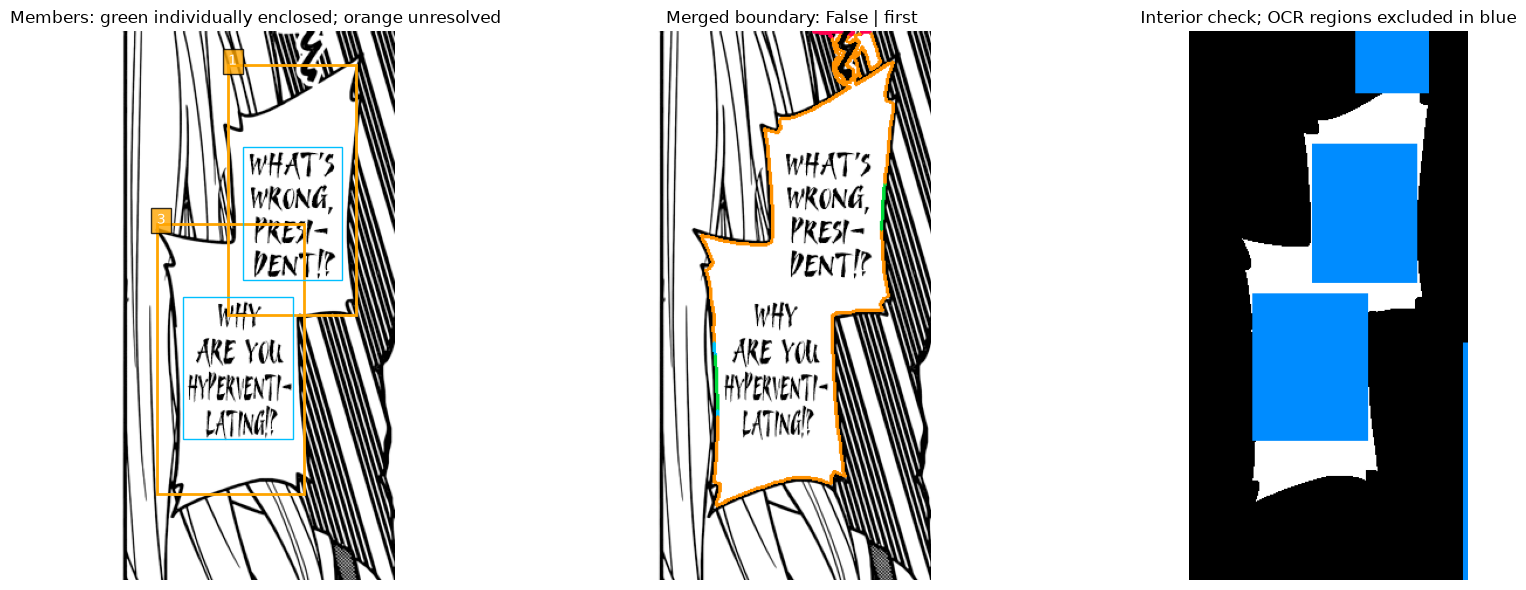

,detection_pass,faint_retry_attempted,merge_index,candidate_ids,individually_verified,unresolved_candidate_ids,associated_text_indices,merged_box,enclosed_boundary_found,helps_candidate_ids,...,border_dark_fraction,margin_px,shape,flat_fraction,curved_fraction,sharp_fraction,crop_edge_fraction,supported_boundary_fraction,longest_unsupported_fraction,crop_truncated
0,first,True,0,"[1, 3]",[],"[1, 3]","[5, 6]","[79, 28, 249, 395]",False,[],...,0.499307,14.0,ambiguous,0.012245,0.061224,0.926531,0.042969,0.703125,0.285156,True


In [8]:
def inspect_merge(merge_index=0):
    if not merge_results:
        print('No merge attempts for this page.')
        return
    item=merge_results[merge_index]
    row,result=item['row'],item['check']
    best=result['boundary_best'] or result['best']
    left,top,_,_=result['bounds']
    fig,axes=plt.subplots(1,3,figsize=(18,6))
    axes[0].imshow(result['crop'])
    for i in row['candidate_ids']:
        a,b,c,d=candidates[i]['box']
        color='limegreen' if checks[i]['enclosed_boundary_found'] else 'orange'
        axes[0].add_patch(patches.Rectangle((a-left,b-top),c-a,d-b,fill=False,edgecolor=color,linewidth=2))
        axes[0].text(a-left,b-top,str(i),color='white',bbox=dict(facecolor=color,alpha=.8))
    for i in row['associated_text_indices']:
        a,b,c,d=texts[i]
        axes[0].add_patch(patches.Rectangle((a-left,b-top),c-a,d-b,fill=False,edgecolor='deepskyblue',linewidth=1))
    axes[0].set_title('Members: green individually enclosed; orange unresolved')
    overlay=result['crop'].copy()
    measured=np.zeros_like(overlay)
    if best:
        points=np.rint(best['boundary_points']).astype(int)
        colors={'flat':(0,200,255),'curved':(0,220,60),'sharp':(255,145,0),'crop_edge':(255,0,80)}
        for i,label in enumerate(best['boundary_labels']):
            cv2.line(overlay,tuple(points[i]),tuple(points[(i+1)%len(points)]),colors[label],2)
        measured[best['usable']]=(255,255,255)
        gray=cv2.cvtColor(result['crop'],cv2.COLOR_RGB2GRAY)
        measured[best['usable']&(gray<CHECK['white_threshold'])]=(255,60,60)
    measured[result['text_mask']>0]=(0,140,255)
    axes[1].imshow(overlay)
    axes[1].set_title(f"Merged boundary: {row['enclosed_boundary_found']} | {row['detection_pass']}")
    axes[2].imshow(measured)
    axes[2].set_title('Interior check; OCR regions excluded in blue')
    for ax in axes: ax.axis('off')
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame([row]))
    if row['enclosed_boundary_found']:
        print('Boundary helps unresolved candidates:',row['helps_candidate_ids'])
        print('Passing all shape/white checks:',row['passes_all_checks'])


if merge_results:
    merge_selector=widgets.Dropdown(options=[
        (f"{r['row']['merge_index']}: {r['row']['candidate_ids']} | boundary={r['row']['enclosed_boundary_found']}",i)
        for i,r in enumerate(merge_results)],description='Merge:')
    display(widgets.interactive(inspect_merge,merge_index=merge_selector))
    inspect_merge(0)  # Direct call works if widgets are unavailable.
else:
    print('No merged crop to display.')
# Inspect another result directly: inspect_merge(1)


## 9. Optional export

Export inspection scores/settings only when enabled. Existing pipeline caches, checkpoints and decisions are never modified.

In [9]:
SAVE_INSPECTION = False
if SAVE_INSPECTION:
    output=CACHE / ('inspection_' + PAGE_HASH[:12] + '_' + key(CHECK)[:12])
    output.mkdir(exist_ok=True)
    scores.to_csv(output/'contour_scores.csv',index=False)
    merge_scores.to_csv(output/'merge_scores.csv',index=False)
    boundary_summary.to_csv(output/'boundary_summary.csv',index=False)
    (output/'settings.json').write_text(json.dumps(dict(page=str(PAGE_PATH),page_hash=PAGE_HASH,
        check=CHECK,faint_retry=FAINT,text_source=text_source,bubble_source=bubble_source),indent=2),encoding='utf-8')
    print('Saved:',output)
# To inspect another candidate directly: inspect_candidate(2)
# After changing CHECK thresholds, rerun cells 5 and 6; no detectors need to run again.


## Bubble-to-Magi grouping demo
Run after the individual and merge checks. This adds grouped OCR rows only; no narration classifier or full inference pipeline runs. Verified closed boundaries mark their assigned texts SPOKEN (including rectangular boundaries). Overlap proposals also join texts when no merged outline is found; joining alone does not imply SPOKEN. Unmatched texts remain standalone and UNRESOLVED. Speaker labels below are page-local Magi character clusters, not the full pipeline's trained character identities.

### Load matching OCR and character links
Reuse the exact cached Magi page and selected OCR when available. If absent, the next cell runs the local Magi model once with OCR enabled and aligns its boxes back to the existing boxes. It does not replace detector or contour results.


In [10]:
def load_grouping_magi():
    roots=[EXPERIMENT/'cache_selected_ocr/full_pipeline', PROJECT/'paddleOCR-Magi/cache_inference']
    for root in roots:
        for manifest_path in sorted(root.rglob('manifest.json')):
            try:
                manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
                raw_path=manifest_path.with_name('magi_raw.json')
                payload=json.loads(raw_path.read_text(encoding='utf-8'))
                digest=hashlib.sha256(json.dumps(payload['data'],sort_keys=True,
                    ensure_ascii=True,allow_nan=False).encode()).hexdigest()
                if digest!=payload['data_hash']: continue
                for index,page in enumerate(manifest['inputs']['pages']):
                    if page['sha256']!=PAGE_HASH: continue
                    raw=payload['data'][index]
                    if not np.allclose(np.asarray(raw['texts']),np.asarray(texts),atol=0.01): continue
                    selected=list(raw['ocr'])
                    details=[{} for _ in selected]
                    selection_path=manifest_path.with_name('ocr_selection.json')
                    if selection_path.is_file():
                        selection=json.loads(selection_path.read_text(encoding='utf-8'))
                        checksum=hashlib.sha256(json.dumps(selection['data'],sort_keys=True,
                            ensure_ascii=True,allow_nan=False).encode()).hexdigest()
                        decisions=selection['data'][index]
                        if checksum==selection['data_hash'] and len(decisions)==len(texts) and all(
                            np.allclose(v['box'],b,atol=.01) for v,b in zip(decisions,texts)):
                            selected=[v['selected_text'] for v in decisions]
                            details=[dict(disagreement=v.get('disagreement',False),
                                needs_review=v.get('needs_review',False),
                                confidence=min([line['confidence'] for line in v.get('paddle_lines',[])],default=None)
                                    if v.get('selected_source')=='paddle' else None) for v in decisions]
                    return raw,selected,list(range(len(texts))),str(raw_path),details
            except (OSError,KeyError,ValueError,IndexError,TypeError):
                continue
    # Separate lightweight JSON cache for this demo's optional OCR fallback.
    identity=dict(page=PAGE_HASH,model=str(MAGI_MODEL),
        weights={p.name:sha256(p) for p in MAGI_MODEL.glob('*.safetensors')},version=1)
    path=CACHE/('grouping_ocr_'+key(identity)[:20]+'.json')
    if path.is_file():
        raw=json.loads(path.read_text(encoding='utf-8'))
    else:
        from transformers import AutoConfig,AutoModel
        config=AutoConfig.from_pretrained(str(MAGI_MODEL),trust_remote_code=True,local_files_only=True)
        config.detection_model_config.use_pretrained_backbone=False
        config.disable_ocr=False
        config.disable_detections=False
        model=AutoModel.from_pretrained(str(MAGI_MODEL),config=config,
            trust_remote_code=True,local_files_only=True).to(DEVICE).eval()
        try:
            with torch.inference_mode():
                raw=model.do_chapter_wide_prediction([np.asarray(image.convert('L').convert('RGB'))],
                    {'images':[],'names':[]},do_ocr=True)[0]
            path.write_text(json.dumps(raw,ensure_ascii=False),encoding='utf-8')
        finally:
            del model
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    # Never assume indices from a new prediction match the original detection cache.
    from scipy.optimize import linear_sum_assignment
    a=np.asarray(texts,dtype=float).reshape(-1,4)
    b=np.asarray(raw['texts'],dtype=float).reshape(-1,4)
    inter=np.maximum(0,np.minimum(a[:,None,2:],b[None,:,2:])-
                        np.maximum(a[:,None,:2],b[None,:,:2])).prod(-1)
    union=(a[:,2:]-a[:,:2]).prod(-1)[:,None]+(b[:,2:]-b[:,:2]).prod(-1)[None,:]-inter
    iou=inter/np.maximum(union,1e-9)
    rows,cols=linear_sum_assignment(-np.where(iou>=.95,len(a)+1+iou,-1))
    assert len(rows)==len(a) and (iou[rows,cols]>=.95).all(), 'OCR boxes changed: use matching caches.'
    mapping=np.empty(len(a),dtype=int);mapping[rows]=cols
    # Original text IDs stay intact; raw indices supply reading order and character links.
    return raw,[raw['ocr'][i] for i in mapping],mapping.tolist(),str(path),[{} for _ in mapping]

magi_grouping,grouping_ocr,raw_indices,grouping_ocr_source,grouping_ocr_details=load_grouping_magi()
print('Grouping OCR:',grouping_ocr_source)


Grouping OCR: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_contour\grouping_ocr_2765199bc9ec376f657c.json


### Assign texts and concatenate each group
All selected overlap groups join their associated Magi texts, regardless of the merged boundary result. Prefer the full connected group over its smaller pairs; conflicting proposals are flagged. Use the existing member-to-Magi matches (80% original box coverage), then concatenate in Magi reading order. Individual verified bubbles still use contour coverage (95%). Each text appears once. Boundary results remain visible and control SPOKEN status only; an unverified merged group stays UNRESOLVED for later classification.

English artifact filter: Japanese/CJK and empty selected OCR are excluded from transcript rows but retained in the assignment table and red preview boxes. Punctuation and short Latin text are preserved. Available low confidence/disagreement flags trigger review only. SPOKEN grouping additionally requires a mostly white interior and at least 10% contour area outside the OCR rectangles; this is not the removed bbox-margin rule. Existing contour verification results are unchanged.


In [11]:
# English transcript filtering: uncertain Latin OCR stays visible for review.
ARTIFACT_FILTER=dict(enabled=True, min_ocr_confidence=0.70,
                     min_surrounding_fraction=0.10)

def artifact_decision(text, detail):
    import re
    text=str(text or '').strip()
    japanese=bool(re.search(r'[\u3040-\u30ff\u31f0-\u31ff\uff66-\uff9f\u3400-\u4dbf\u4e00-\u9fff\uf900-\ufaff\U00020000-\U0002fa1f]',text))
    excluded=ARTIFACT_FILTER['enabled'] and (japanese or not text)
    reason='Japanese/CJK OCR in English transcript' if japanese else 'empty OCR' if not text else ''
    confidence=detail.get('confidence')
    review=bool(detail.get('disagreement') or detail.get('needs_review') or
                (confidence is not None and confidence<ARTIFACT_FILTER['min_ocr_confidence']))
    return dict(excluded_artifact=bool(excluded),artifact_reason=reason if excluded else '',
                ocr_needs_review=review,ocr_confidence=confidence)

def usable_bubble(result):
    """Enclosure alone may trace a glyph: require white space around the OCR region."""
    if not result['enclosed_boundary_found']: return False
    # Choose an enclosed contour passing the interior tests, if one exists.
    for boundary in sorted(result['contours'],key=lambda b:-b['score']):
        if not boundary['enclosed_boundary_found']: continue
        inside=boundary['mask']>0
        surrounding=np.count_nonzero(inside & (result['required']==0))/max(1,np.count_nonzero(inside))
        if (boundary['white_fraction']>=CHECK['min_white_fraction'] and
            surrounding>=ARTIFACT_FILTER['min_surrounding_fraction']):
            return boundary
    return False

def make_transcript_groups(candidate_list,individual_checks,merges,text_boxes,ocr,raw_order,raw):
    height,width=image.height,image.width
    proposals=[]
    # Every selected overlap proposal qualifies for text joining, even if its contour failed.
    selected=sorted(merges,key=lambda m:(-len(m['row']['candidate_ids']),m['row']['merge_index']))
    consumed=set()
    conflicting=[]
    for item in selected:
        members=set(item['row']['candidate_ids'])
        if members & consumed:
            conflicting.append(item['row']['merge_index'])
            continue
        proposals.append((f"M{item['row']['merge_index']}",item['check'],'overlap_merge',sorted(members)))
        consumed.update(members)
    for i,result in enumerate(individual_checks):
        if i not in consumed and usable_bubble(result) is not False:
            proposals.append((f'B{i}',result,'verified_individual',[i]))
    groups=[]
    for gid,result,source,members in proposals:
        mask=np.zeros((height,width),np.uint8)
        if source=='overlap_merge':
            # Match to the selected YOLO members themselves. A merged outline is NOT required.
            text_ids=sorted({t for i in members for t in individual_checks[i]['associated_text_indices']})
            for i in members:
                a,b,c,d=candidate_list[i]['box']
                mask[max(0,int(b)):min(height,int(d)),max(0,int(a)):min(width,int(c))]=255
        else:
            text_ids=result['associated_text_indices']
            left,top,right,bottom=result['bounds']
            mask[top:bottom,left:right]=usable_bubble(result)['mask']
        groups.append(dict(group_id=gid,mask=mask,area=int(np.count_nonzero(mask)),
            group_source=source,candidate_ids=members,text_ids=text_ids,
            boundary_verified=usable_bubble(result) is not False))
    # Preserve individual SPOKEN decisions even inside an unverified merged group.
    individually_spoken={t for r in individual_checks if usable_bubble(r) is not False
                         for t in r['associated_text_indices']}
    assignments=[]
    for i,box in enumerate(text_boxes):
        a,b,c,d=box
        left,top=max(0,math.floor(a)),max(0,math.floor(b))
        right,bottom=min(width,math.ceil(c)),min(height,math.ceil(d))
        decision=artifact_decision(ocr[i],grouping_ocr_details[i])
        options=[]
        # Use the full rasterized text-box area; clipping does not inflate coverage.
        area=max(1,(math.ceil(c)-math.floor(a))*(math.ceil(d)-math.floor(b)))
        for g in ([] if decision['excluded_artifact'] else groups):
            coverage=np.count_nonzero(g['mask'][top:bottom,left:right])/area
            # Selected merge members already have Magi matches from the original 80% box test.
            qualifies=(i in g['text_ids']) if g['group_source']=='overlap_merge' else coverage>=CHECK['min_text_coverage']
            if qualifies:
                options.append((float(coverage),g['area'],g['group_id']))
        options.sort(key=lambda v:(-v[0],v[1],v[2]))
        gid=options[0][2] if options else f'T{i}'
        spoken=(i in individually_spoken or any(g['group_id']==gid and g['boundary_verified'] for g in groups))
        assignments.append(dict(text_role='SPOKEN' if spoken and not decision['excluded_artifact'] else 'UNRESOLVED',text_index=i,box_id=f'PG{PAGE_NUMBER}:T{i+1}',
            group_id=gid,coverage=options[0][0] if options else 0.,
            alternatives=[v[2] for v in options[1:]],assignment_ambiguous=len(options)>1,**decision))
    lookup={g['group_id']:g for g in groups}
    rows=[]
    for gid in dict.fromkeys(a['group_id'] for a in assignments if not a['excluded_artifact']):
        members=sorted([a for a in assignments if a['group_id']==gid],key=lambda a:raw_order[a['text_index']])
        ids=[a['text_index'] for a in members]
        speakers=set()
        for i in ids:
            for t,c in raw.get('text_character_associations',[]):
                if t==raw_order[i]:
                    cluster=raw.get('character_cluster_labels',list(range(len(raw['characters']))))[c]
                    speakers.add(f'PG{PAGE_NUMBER}:CHAR_CLUSTER_{cluster}')
        grouped=gid in lookup
        verified=grouped and lookup[gid]['boundary_verified']
        rows.append(dict(group_id=f'PG{PAGE_NUMBER}:{gid}',
            box_ids=[a['box_id'] for a in members],
            text=' '.join(str(ocr[i]).strip() for i in ids if str(ocr[i]).strip()),
            text_role='SPOKEN' if all(a['text_role']=='SPOKEN' for a in members) else 'UNRESOLVED',
            member_text_roles=[a['text_role'] for a in members],
            speaker=next(iter(speakers)) if len(speakers)==1 else 'UNKNOWN',
            speaker_candidates=sorted(speakers),
            group_source=lookup[gid]['group_source'] if grouped else 'standalone',
            boundary_verified=bool(verified),
            candidate_ids=lookup[gid]['candidate_ids'] if grouped else [],
            needs_review=any(a['assignment_ambiguous'] for a in members) or any(a['ocr_needs_review'] for a in members) or len(speakers)!=1 or not verified,
            reading_position=min(raw_order[i] for i in ids)))
    rows.sort(key=lambda r:r['reading_position'])
    return rows,assignments,groups,conflicting

grouped_rows,text_assignments,transcript_groups,conflicting_merges=make_transcript_groups(
    candidates,checks,merge_results,texts,grouping_ocr,raw_indices,magi_grouping)
assert sum(len(r['box_ids']) for r in grouped_rows)==sum(not a['excluded_artifact'] for a in text_assignments)
assert len({bid for r in grouped_rows for bid in r['box_ids']})==sum(not a['excluded_artifact'] for a in text_assignments)
display(pd.DataFrame(grouped_rows))
display(pd.DataFrame(text_assignments))
excluded_artifacts=[dict(a,text=grouping_ocr[a['text_index']]) for a in text_assignments if a['excluded_artifact']]
display(pd.DataFrame(excluded_artifacts))
print('Conflicting merge proposals skipped for review:',conflicting_merges)
for row in grouped_rows:
    print(f"{row['group_id']} | {row['text_role']} | {row['speaker']}: {row['text']}")


,group_id,box_ids,text,text_role,member_text_roles,speaker,speaker_candidates,group_source,boundary_verified,candidate_ids,needs_review,reading_position
0,PG2:T0,[PG2:T1],GHA. AAA!!!,UNRESOLVED,[UNRESOLVED],PG2:CHAR_CLUSTER_3,[PG2:CHAR_CLUSTER_3],standalone,False,[],True,0
1,PG2:B2,[PG2:T2],Gaaaaay. Hhhh!!,SPOKEN,[SPOKEN],PG2:CHAR_CLUSTER_3,[PG2:CHAR_CLUSTER_3],verified_individual,True,[2],False,1
2,PG2:T2,[PG2:T3],to,UNRESOLVED,[UNRESOLVED],PG2:CHAR_CLUSTER_3,[PG2:CHAR_CLUSTER_3],standalone,False,[],True,2
3,PG2:T3,[PG2:T4],$5,UNRESOLVED,[UNRESOLVED],PG2:CHAR_CLUSTER_3,[PG2:CHAR_CLUSTER_3],standalone,False,[],True,3
4,PG2:T4,[PG2:T5],Stiles,UNRESOLVED,[UNRESOLVED],UNKNOWN,[],standalone,False,[],True,4
5,PG2:M0,"[PG2:T6, PG2:T7]","WHAT'S WRONG, PREST- DENT!?!? WHY ARE YOU HY...",UNRESOLVED,"[UNRESOLVED, UNRESOLVED]",PG2:CHAR_CLUSTER_2,[PG2:CHAR_CLUSTER_2],overlap_merge,False,"[1, 3]",True,5
6,PG2:M1,"[PG2:T8, PG2:T9]",I can't... Miyuki Shirogane Wants to Prepare,UNRESOLVED,"[SPOKEN, UNRESOLVED]",PG2:CHAR_CLUSTER_0,[PG2:CHAR_CLUSTER_0],overlap_merge,False,"[6, 9]",True,7
7,PG2:T9,[PG2:T10],Chapter 49,UNRESOLVED,[UNRESOLVED],PG2:CHAR_CLUSTER_0,[PG2:CHAR_CLUSTER_0],standalone,False,[],True,9
8,PG2:T10,[PG2:T11],An,UNRESOLVED,[UNRESOLVED],PG2:CHAR_CLUSTER_1,[PG2:CHAR_CLUSTER_1],standalone,False,[],True,10
9,PG2:B8,[PG2:T12],I know I'm good at cooking...,SPOKEN,[SPOKEN],PG2:CHAR_CLUSTER_1,[PG2:CHAR_CLUSTER_1],verified_individual,True,[8],False,11


,text_role,text_index,box_id,group_id,coverage,alternatives,assignment_ambiguous,excluded_artifact,artifact_reason,ocr_needs_review,ocr_confidence
0,UNRESOLVED,0,PG2:T1,T0,0.000000,[],False,False,,False,None
1,SPOKEN,1,PG2:T2,B2,0.986488,[],False,False,,False,None
2,UNRESOLVED,2,PG2:T3,T2,0.000000,[],False,False,,False,None
3,UNRESOLVED,3,PG2:T4,T3,0.000000,[],False,False,,False,None
4,UNRESOLVED,4,PG2:T5,T4,0.000000,[],False,False,,False,None
5,UNRESOLVED,5,PG2:T6,M0,1.000000,[],False,False,,False,None
6,UNRESOLVED,6,PG2:T7,M0,1.000000,[],False,False,,False,None
7,SPOKEN,7,PG2:T8,M1,1.000000,[],False,False,,False,None
8,UNRESOLVED,8,PG2:T9,M1,0.982301,[],False,False,,False,None
9,UNRESOLVED,9,PG2:T10,T9,0.000000,[],False,False,,False,None


""


Conflicting merge proposals skipped for review: []
PG2:T0 | UNRESOLVED | PG2:CHAR_CLUSTER_3: GHA. AAA!!!
PG2:B2 | SPOKEN | PG2:CHAR_CLUSTER_3: Gaaaaay. Hhhh!!
PG2:T2 | UNRESOLVED | PG2:CHAR_CLUSTER_3: to
PG2:T3 | UNRESOLVED | PG2:CHAR_CLUSTER_3: $5
PG2:T4 | UNRESOLVED | UNKNOWN: Stiles
PG2:M0 | UNRESOLVED | PG2:CHAR_CLUSTER_2: WHAT'S WRONG,  PREST-  DENT!?!? WHY ARE YOU HYEKVENTI- LATING!!?
PG2:M1 | UNRESOLVED | PG2:CHAR_CLUSTER_0: I can't... Miyuki Shirogane Wants to Prepare
PG2:T9 | UNRESOLVED | PG2:CHAR_CLUSTER_0: Chapter 49
PG2:T10 | UNRESOLVED | PG2:CHAR_CLUSTER_1: An
PG2:B8 | SPOKEN | PG2:CHAR_CLUSTER_1: I know I'm good at cooking...
PG2:B7 | SPOKEN | PG2:CHAR_CLUSTER_1: But not this!
PG2:B10 | SPOKEN | PG2:CHAR_CLUSTER_0: Anything but fish!!
PG2:B12 | SPOKEN | PG2:CHAR_CLUSTER_0: How much!?
PG2:B11 | SPOKEN | PG2:CHAR_CLUSTER_1: Cooking practice!!


### View the groups and optionally save this demo
Same-colored text rectangles belong to the same transcript row. Verified individual contours and selected YOLO merge regions are shown in matching colors. A merge-region outline in this preview does not claim a verified drawn boundary. This does not modify existing caches or the full pipeline's exports.


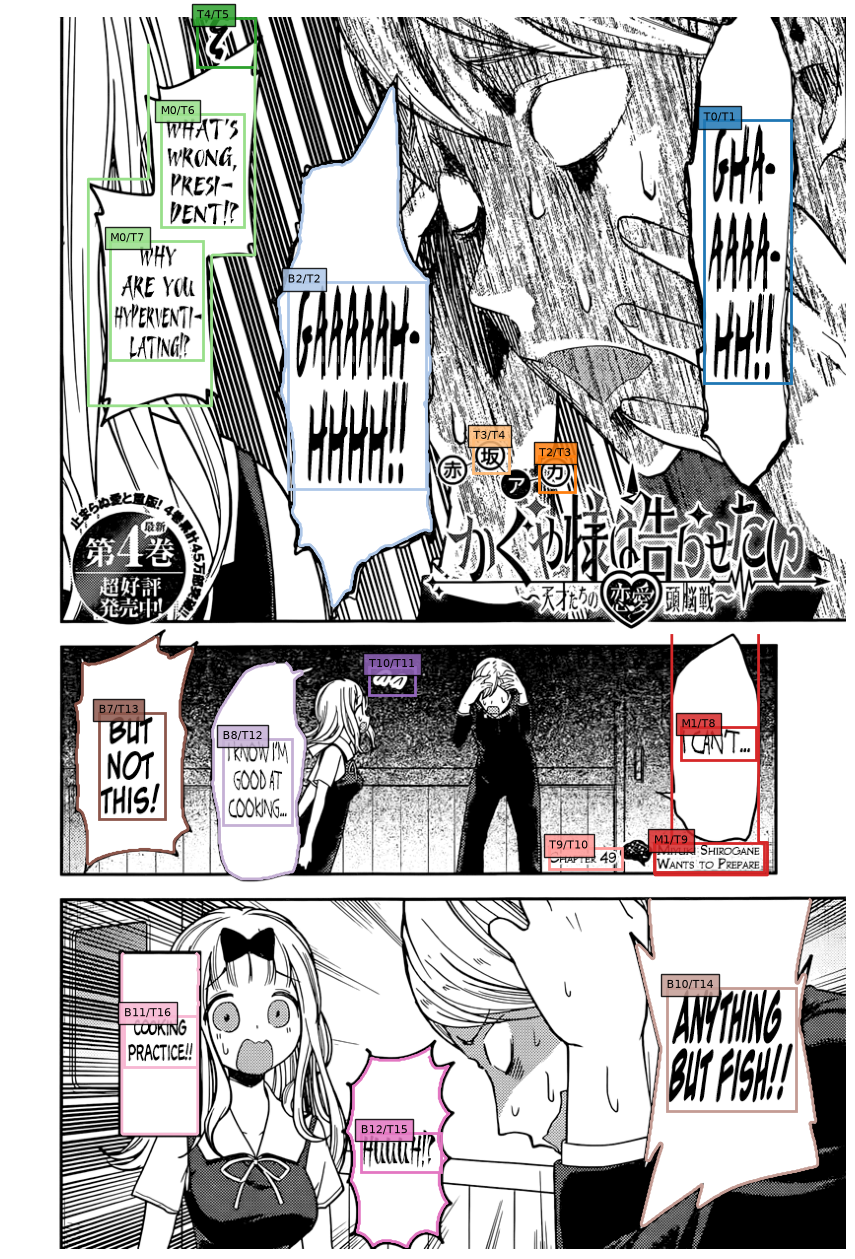

In [12]:
fig,ax=plt.subplots(figsize=(12,16))
ax.imshow(image)
for number,row in enumerate(grouped_rows):
    color=plt.get_cmap('tab20')(number%20)
    gid=row['group_id'].split(':',1)[1]
    group=next((g for g in transcript_groups if g['group_id']==gid),None)
    if group:
        outline,_=cv2.findContours(group['mask'],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        for contour in outline:
            points=contour[:,0]
            ax.plot(points[:,0],points[:,1],color=color,linewidth=2)
    for assignment in text_assignments:
        if assignment['group_id']!=gid: continue
        a,b,c,d=texts[assignment['text_index']]
        ax.add_patch(patches.Rectangle((a,b),c-a,d-b,fill=False,edgecolor=color,linewidth=2))
        ax.text(a,b,f"{gid}/T{assignment['text_index']+1}",color='black',
                bbox=dict(facecolor=color,alpha=.85),fontsize=8)
# Excluded boxes stay visible in red, with their original IDs.
for item in excluded_artifacts:
    a,b,c,d=texts[item['text_index']]
    ax.add_patch(patches.Rectangle((a,b),c-a,d-b,fill=False,edgecolor='red',linewidth=2,linestyle='--'))
    ax.text(a,b,'EXCLUDED '+item['box_id'],color='red',fontsize=8)
ax.axis('off');plt.show()

SAVE_GROUPING=False
if SAVE_GROUPING:
    folder=CACHE/('grouping_'+PAGE_HASH[:12]+'_'+key(dict(check=CHECK,faint=FAINT,artifact=ARTIFACT_FILTER))[:12])
    folder.mkdir(exist_ok=True)
    pd.DataFrame(grouped_rows).to_csv(folder/'grouped_transcript.csv',index=False)
    (folder/'grouped_transcript.json').write_text(json.dumps(grouped_rows,indent=2,ensure_ascii=False),encoding='utf-8')
    (folder/'assignments.json').write_text(json.dumps(text_assignments,indent=2),encoding='utf-8')
    (folder/'excluded_artifacts.json').write_text(json.dumps(excluded_artifacts,indent=2,ensure_ascii=False),encoding='utf-8')
    (folder/'artifact_filter.json').write_text(json.dumps(ARTIFACT_FILTER,indent=2),encoding='utf-8')
    fig.savefig(folder/'groups.png',bbox_inches='tight')
    print('Saved:',folder)
